# Лабораторная работа №5-6:

Подготовка данных и реализация алгоритма Fuzzy C-Means (FCM)

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

# Загрузка данных
df = pd.read_csv('../ML-Dataset_cleaned.csv')
features = ['ProductListPrice', 'CustomerCreditLimit', 'Profit_Per_Unit',
            'TotalItemQuantity', 'PerUnitPrice']
# Подготовка данных
X = df[features].copy()
X = X.dropna()
# Стандартизация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"Размер данных: {X_scaled.shape[0]} наблюдений, {X_scaled.shape[1]} признаков")
print(f"Признаки: {', '.join(features)}\n")

#реализация Fuzzy C-Means
class FuzzyCMeans:

    def __init__(self, n_clusters=3, m=2.0, max_iter=150, epsilon=0.005, random_state=42):
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.epsilon = epsilon
        self.random_state = random_state
        np.random.seed(random_state)

    def _initialize_membership(self, n_samples):
        """Инициализация матрицы принадлежности"""
        u = np.random.rand(n_samples, self.n_clusters)
        u = u / u.sum(axis=1, keepdims=True)
        return u

    def _update_centers(self, X, u):
        """Обновление центров кластеров"""
        um = u ** self.m
        centers = np.dot(um.T, X) / um.sum(axis=0)[:, np.newaxis]
        return centers

    def _update_membership(self, X, centers):
        """Обновление матрицы принадлежности"""
        n_samples = X.shape[0]
        u = np.zeros((n_samples, self.n_clusters))
        for i in range(n_samples):
            distances = np.linalg.norm(X[i] - centers, axis=1)
            zero_dist_mask = distances == 0
            if np.any(zero_dist_mask):
                u[i, zero_dist_mask] = 1.0
                u[i, ~zero_dist_mask] = 0.0
            else:
                power = 2.0 / (self.m - 1)
                for j in range(self.n_clusters):
                    denominator = np.sum((distances[j] / (distances + 1e-10)) ** power)
                    u[i, j] = 1.0 / (denominator + 1e-10)

        u = u / u.sum(axis=1, keepdims=True)
        return u

    def fit(self, X):
        """Обучение модели FCM"""
        n_samples = X.shape[0]
        self.u = self._initialize_membership(n_samples)
        for iteration in range(self.max_iter):
            u_old = self.u.copy()
            self.centers = self._update_centers(X, self.u)
            self.u = self._update_membership(X, self.centers)
            if np.linalg.norm(self.u - u_old) < self.epsilon:
                print(f"    Сходимость достигнута на итерации {iteration + 1}")
                break
        return self
    def predict(self, X):
        """Предсказание жестких меток"""
        if not hasattr(self, 'centers'):
            raise ValueError("Модель не обучена")
        u = self._update_membership(X, self.centers)
        return np.argmax(u, axis=1)



Размер данных: 400 наблюдений, 5 признаков
Признаки: ProductListPrice, CustomerCreditLimit, Profit_Per_Unit, TotalItemQuantity, PerUnitPrice



##  Кластеризация с различными значениями параметрами нечеткости m

In [105]:
# 1. Жесткая кластеризация (K-Means) для сравнения
print("1. Жесткая кластеризация (K-Means)")
print("-" * 40)
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_centers = kmeans.cluster_centers_

print(f"Количество кластеров: {n_clusters}")
print(f"Распределение точек по кластерам:")
for i in range(n_clusters):
    count = np.sum(kmeans_labels == i)
    print(f"  Кластер {i}: {count} точек ({count/len(kmeans_labels)*100:.1f}%)")

# 2. Мягкая кластеризация (Fuzzy C-Means) с разными параметрами
print("\n2. Мягкая кластеризация (Fuzzy C-Means")
print("-" * 40)
def run_fcm(X_scaled, n_clusters, m, max_iter=150, epsilon=0.005):
    """Запуск FCM с заданными параметрами"""
    fcm = FuzzyCMeans(n_clusters=n_clusters, m=m, max_iter=max_iter, epsilon=epsilon)
    fcm.fit(X_scaled)
    return fcm

# Параметры для экспериментов
m_values = [1.5, 2.0, 2.5,3.0]
#m_values = [1.1, 1.8, 2.0,2.5]
fcm_results = {}

for m in m_values:
    print(f"\nЗапуск FCM с m = {m}")
    fcm = run_fcm(X_scaled, n_clusters, m)
    fcm_results[m] = fcm

    hard_labels = np.argmax(fcm.u, axis=1)

    print(f"  Распределение точек по кластерам (жесткое):")
    for i in range(n_clusters):
        count = np.sum(hard_labels == i)
        print(f"    Кластер {i}: {count} точек ({count/len(hard_labels)*100:.1f}%)")

    entropy = -np.sum(fcm.u * np.log(fcm.u + 1e-10), axis=1).mean()
    print(f"  Средняя энтропия принадлежности: {entropy:.4f}")

print("\n3. ВЫБОР 5 ТОЧЕК ДЛЯ АНАЛИЗА ПРИНАДЛЕЖНОСТИ")
print("-" * 40)

# Фиксированный набор из 5 ключевых точек   287
selected_indices = [287, 299, 306, 234, 245, 235]
selected_types = ['','','','','','']

print(f"Выбрано {len(selected_indices)} точек для анализа:")
for i, (idx, typ) in enumerate(zip(selected_indices, selected_types)):
    print(f"  {i+1}. {typ} (индекс {idx})")

1. Жесткая кластеризация (K-Means)
----------------------------------------
Количество кластеров: 3
Распределение точек по кластерам:
  Кластер 0: 3 точек (0.8%)
  Кластер 1: 226 точек (56.5%)
  Кластер 2: 171 точек (42.8%)

2. Мягкая кластеризация (Fuzzy C-Means
----------------------------------------

Запуск FCM с m = 1.5
    Сходимость достигнута на итерации 25
  Распределение точек по кластерам (жесткое):
    Кластер 0: 193 точек (48.2%)
    Кластер 1: 104 точек (26.0%)
    Кластер 2: 103 точек (25.8%)
  Средняя энтропия принадлежности: 0.5617

Запуск FCM с m = 2.0
    Сходимость достигнута на итерации 49
  Распределение точек по кластерам (жесткое):
    Кластер 0: 179 точек (44.8%)
    Кластер 1: 110 точек (27.5%)
    Кластер 2: 111 точек (27.8%)
  Средняя энтропия принадлежности: 0.9276

Запуск FCM с m = 2.5
    Сходимость достигнута на итерации 80
  Распределение точек по кластерам (жесткое):
    Кластер 0: 190 точек (47.5%)
    Кластер 1: 128 точек (32.0%)
    Кластер 2: 82 то

# Визуализация векторов вероятностей для  точек

Визуализация векторов вероятностей для точек


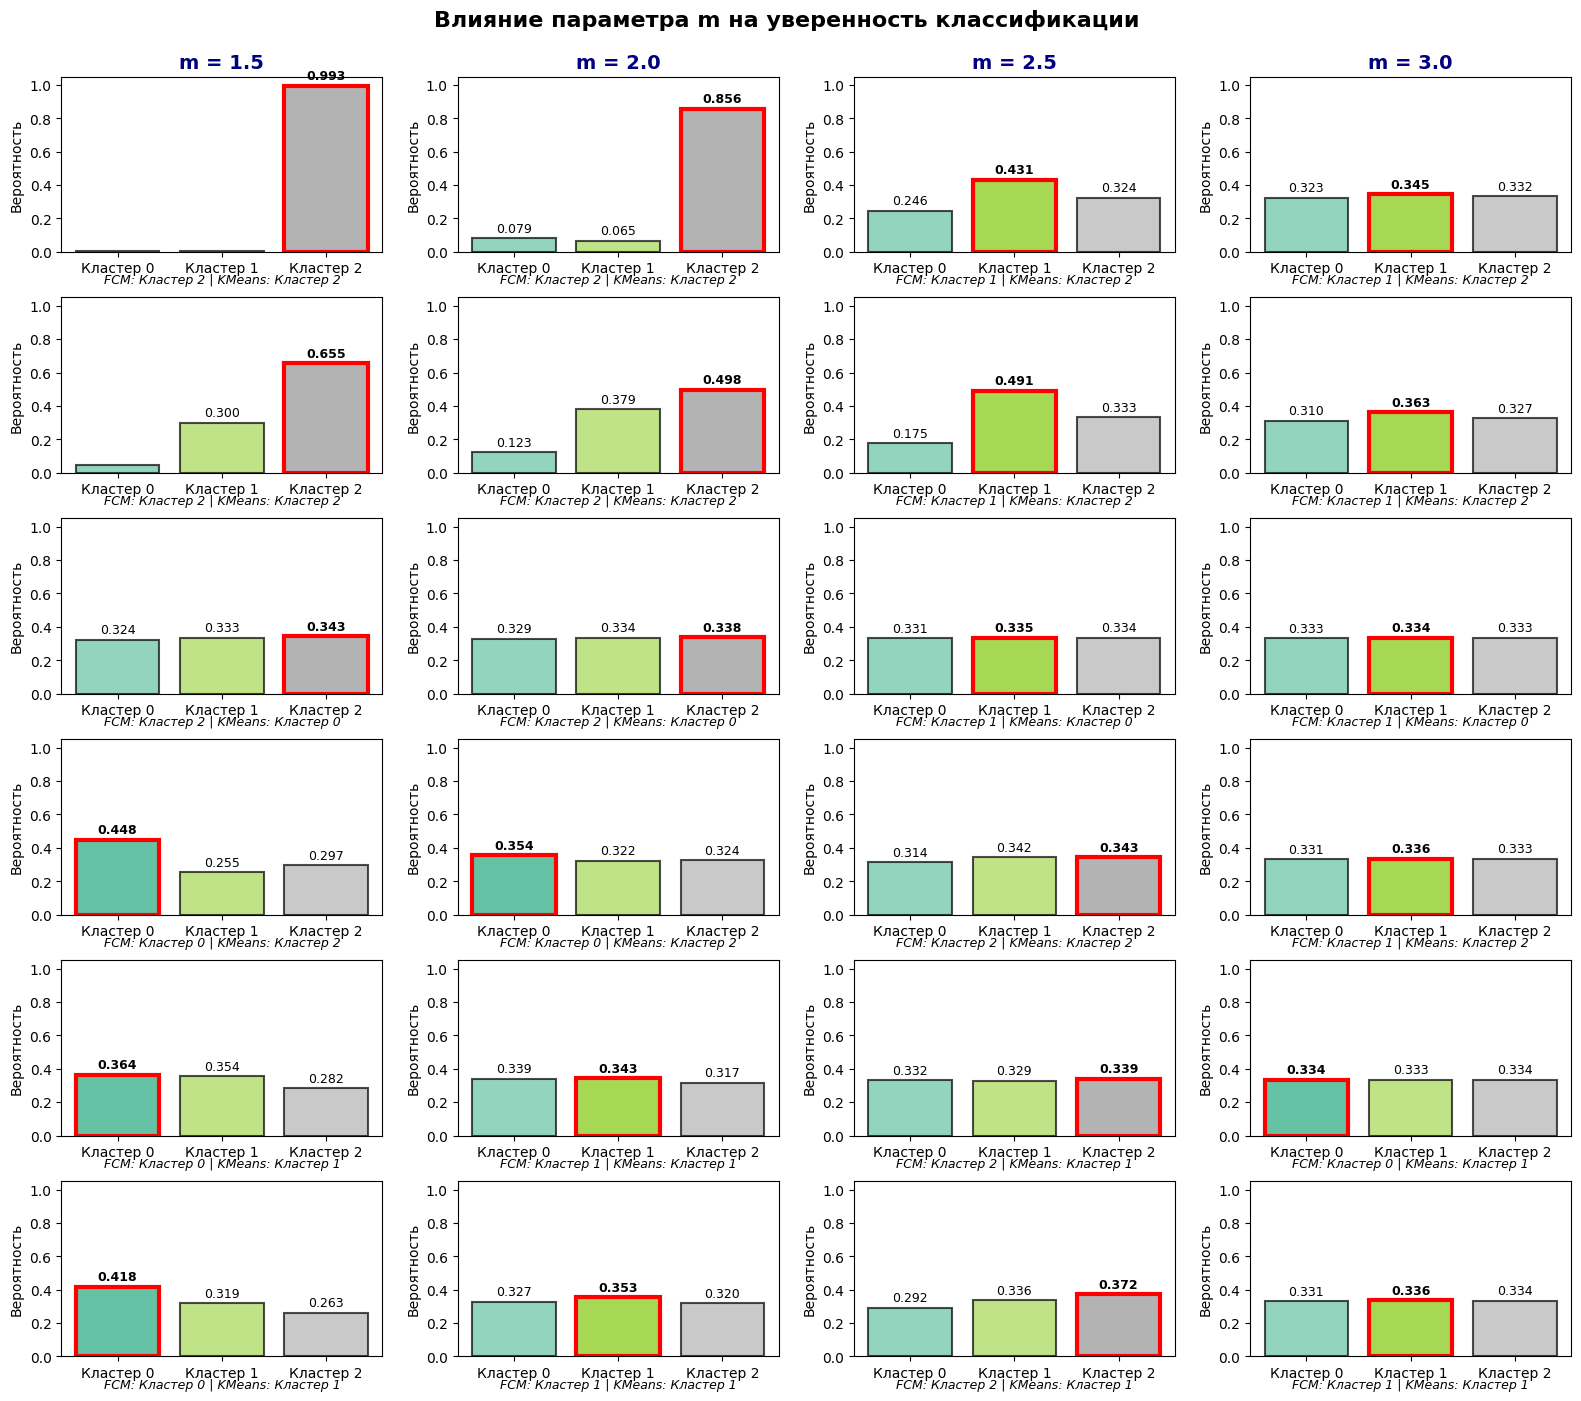

In [106]:
print("Визуализация векторов вероятностей для точек")
def plot_membership_vectors_6points(selected_indices, selected_types, fcm_results, kmeans_labels):

    n_points = len(selected_indices)
    n_m = len(fcm_results)
    n_clusters = list(fcm_results.values())[0].u.shape[1]

    fig, axes = plt.subplots(n_points, n_m, figsize=(16, 14))
    if n_points == 1:
        axes = axes.reshape(1, -1)

    colors = plt.cm.Set2(np.linspace(0, 1, n_clusters))

    for i, (idx, typ) in enumerate(zip(selected_indices, selected_types)):
        for j, (m, fcm) in enumerate(fcm_results.items()):
            ax = axes[i, j]

            # Вероятности принадлежности
            probs = fcm.u[idx]
            hard_label = np.argmax(probs)
            kmeans_label = kmeans_labels[idx]

            # Столбчатая диаграмма
            bars = ax.bar(range(n_clusters), probs, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)

            # Выделяем максимальную вероятность
            bars[hard_label].set_alpha(1.0)
            bars[hard_label].set_edgecolor('red')
            bars[hard_label].set_linewidth(3)

            ax.set_ylim(0, 1.05)
            ax.set_xticks(range(n_clusters))
            ax.set_xticklabels([f'Кластер {k}' for k in range(n_clusters)], fontsize=10)
            ax.set_ylabel('Вероятность', fontsize=10)

            if i == 0:
                ax.set_title(f'm = {m}', fontsize=14, fontweight='bold', color='navy')

            if j == 0:
                # Красивое оформление названия точки
                # Для точки 21 используем особое выделение
                if ' ' in typ:
                    box_color = 'lightgreen'
                else:
                    box_color = 'lightblue'

                ax.text(-0.35, 0.5, typ.replace(': ', '\n'),
                       transform=ax.transAxes, fontsize=10,
                       verticalalignment='center', horizontalalignment='right',
                       bbox=dict(boxstyle='round', facecolor=box_color, alpha=0.7),
                       fontweight='bold')

            # Информация о метках
            ax.text(0.5, -0.18, f'FCM: Кластер {hard_label} | KMeans: Кластер {kmeans_label}',
                   transform=ax.transAxes, fontsize=9, ha='center', style='italic')

            # Значения вероятностей над столбцами
            for bar, prob in zip(bars, probs):
                if prob > 0.05:
                    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
                           f'{prob:.3f}', ha='center', va='bottom', fontsize=9,
                           fontweight='bold' if prob == max(probs) else 'normal')

    plt.suptitle('Влияние параметра m на уверенность классификации',
                 fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()

# Построение графиков
plot_membership_vectors_6points(selected_indices, selected_types, fcm_results, kmeans_labels)

In [108]:
print("Сравнение жестких меток K-Means и FCM")
print("-" * 40)
for m, fcm in fcm_results.items():
    fcm_hard = np.argmax(fcm.u, axis=1)
    agreement = np.mean(fcm_hard == kmeans_labels)
    print(f"m = {m}: согласие с K-Means = {agreement:.2%}")

Сравнение жестких меток K-Means и FCM
----------------------------------------
m = 1.5: согласие с K-Means = 31.75%
m = 2.0: согласие с K-Means = 33.00%
m = 2.5: согласие с K-Means = 12.00%
m = 3.0: согласие с K-Means = 3.50%


## Анализ влияния параметра m на «размытость» границ кластеров


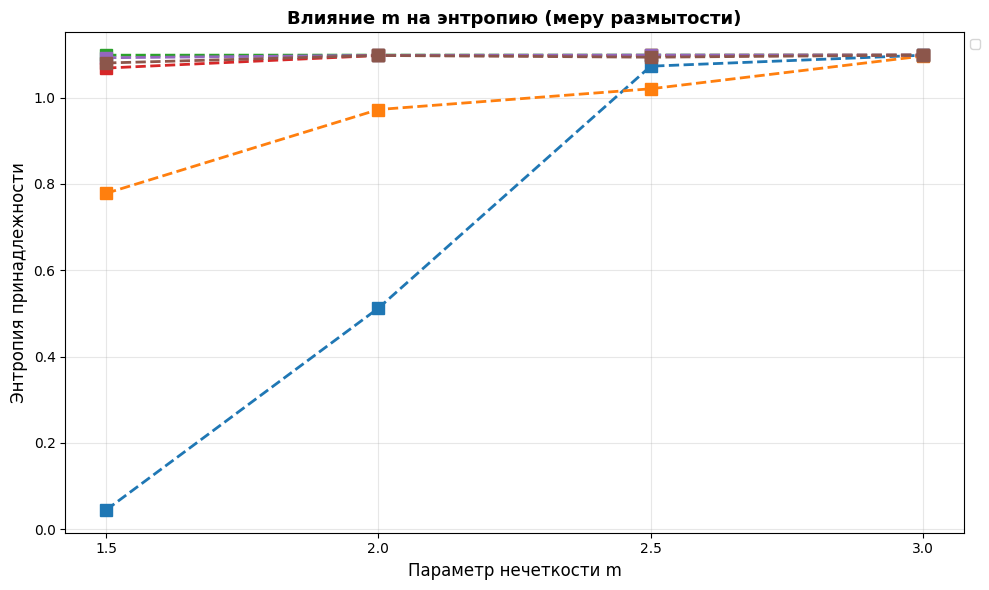

In [115]:
def analyze_fuzziness_6points(fcm_results, selected_indices, selected_types):
    # Создаем одну область для графика
    fig, ax1 = plt.subplots(figsize=(10, 6))
    m_list = sorted(fcm_results.keys())
    for idx, typ in zip(selected_indices, selected_types):
        entropies = []
        for m in m_list:
            u = fcm_results[m].u[idx]
            # Расчет энтропии (меры неопределенности)
            entropy = -np.sum(u * np.log(u + 1e-10))
            entropies.append(entropy)

        # Настройка стиля линий для разных типов точек
        if 'Центр' in typ:
            if 'идеальный' in typ:
                linestyle, marker, linewidth = '-', 'D', 3  # Идеальный центр - жирная линия с ромбами
            else:
                linestyle, marker, linewidth = '-', 'o', 2.5 # Обычные центры
        else:
            linestyle, marker, linewidth = '--', 's', 2 # Граничные/шумовые точки

        ax1.plot(m_list, entropies, marker=marker, linestyle=linestyle,
                linewidth=linewidth, markersize=8, label=typ.replace(': ', '\n'))

    ax1.set_xlabel('Параметр нечеткости m', fontsize=12)
    ax1.set_ylabel('Энтропия принадлежности', fontsize=12)
    ax1.set_title('Влияние m на энтропию (меру размытости)', fontsize=13, fontweight='bold')
    ax1.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=9) # Вынесли легенду в сторону, чтобы не мешала
    ax1.grid(True, alpha=0.3)
    ax1.set_xticks(m_list)

    plt.tight_layout()
    plt.show()

analyze_fuzziness_6points(fcm_results, selected_indices, selected_types)

Влияние $m$ на энтропию (размытость)

Алгоритм относит точки к кластерам уверенно только при низких значениях $m$ ($1.5 \le m < 2.0$). Увеличение параметра m ведет к  росту неопределенности.

- При $m = 1.5$ энтропия минимальна — это значит, что алгоритм четко понимает, какую точку в какой кластер отправить.
А вот при $m = 3.0$ Энтропия достигает предела, и алгоритм просто сдается: он выдает каждой точке вероятность примерно по $33\%$. То есть он больше не видит разницы между группами объектов».

Влияние параметра $m$ на «размытость» границ


С ростом $m$ алгоритм перестает учитывать расстояния до центров. Границы, четкие при $m=1.5$, размываются при $m=2.0$ и полностью исчезают при $m=2.5$.